# Huấn Luyện EfficientNet-B0 (From Scratch) trên Tập Dữ Liệu Mở Rộng 9.301 Ảnh
> **Mục tiêu nghiên cứu:** Đánh giá năng lực của kiến trúc chuẩn mực công nghiệp **EfficientNet-B0 (Tan & Le, 2019)** khi được huấn luyện 100% From Scratch với chiến lược mở rộng dữ liệu tương tự PetNet-Hybrid v2:
> 1. **Tập Huấn luyện mở rộng (9.301 ảnh):** Gộp toàn bộ 3.680 ảnh Oxford-IIIT Pet Trainval + 5.621 ảnh New Dataset (100% ảnh chụp thật đã thẩm định bởi CLIP).
> 2. **Tập Kiểm thử Benchmark Chuẩn (3.669 ảnh):** Đánh giá trực tiếp trên đúng 3.669 ảnh gốc Oxford-IIIT Pet (có tiền xử lý Trimap làm sạch nền).
> 3. **Kiến trúc EfficientNet-B0 (4.05M tham số):** Cấu trúc MBConv (Inverted Residuals + Squeeze-and-Excitation) chuẩn mực.
> 4. **Đánh giá 4-View Multi-Scale TTA:** Đo lường chính xác hiệu quả trước và sau khi kích hoạt TTA.


In [1]:
# [Môi trường Kaggle / Colab] Tự động tải mã nguồn từ GitHub và chuyển vào đúng thư mục làm việc
import os, sys

if os.path.exists("/kaggle"):
    %cd /kaggle/working
    if not os.path.exists("ml-semester-cat-dog-classifier"):
        !git clone https://github.com/LuanNguyen23T/ml-semester-cat-dog-classifier.git
    os.makedirs("ml-semester-cat-dog-classifier/notebooks/15_efficientnet_new_dataset", exist_ok=True)
    %cd /kaggle/working/ml-semester-cat-dog-classifier/notebooks/15_efficientnet_new_dataset
elif os.path.exists("/content"):
    %cd /content
    if not os.path.exists("ml-semester-cat-dog-classifier"):
        !git clone https://github.com/LuanNguyen23T/ml-semester-cat-dog-classifier.git
    os.makedirs("ml-semester-cat-dog-classifier/notebooks/15_efficientnet_new_dataset", exist_ok=True)
    %cd /content/ml-semester-cat-dog-classifier/notebooks/15_efficientnet_new_dataset


## Bước 1: Input các thư viện


In [2]:
import os
import sys
import json
import random
import argparse
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report

current_dir = Path(os.getcwd())
possible_roots = [
    current_dir,
    current_dir.parent,
    current_dir.parent.parent,
    Path("/kaggle/working/ml-semester-cat-dog-classifier"),
    Path("/content/ml-semester-cat-dog-classifier")
]
project_root = None
for p in possible_roots:
    if (p / "src" / "dataset.py").exists():
        project_root = p
        if str(p) not in sys.path:
            sys.path.insert(0, str(p))
        break

from src.dataset import OxfordPetDataset, OxfordPetForegroundDataset, get_transforms

# Cố định seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    torch.mps.manual_seed(SEED)
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Thư mục gốc project: {project_root}")
print(f"Thiết bị tính toán được phân bổ: {device}")


Thư mục gốc project: /Users/nguyenhuuhoangluan/Git_Code/ml-semester-cat-dog-classifier
Thiết bị tính toán được phân bổ: mps


## Bước 2: Thiết lập Tự Động Định Vị & Tải Cả 2 Dataset


In [3]:
def find_dataset_paths():
    """Tự động tìm kiếm đường dẫn cho CẢ 2 tập dữ liệu trên Kaggle, Colab hoặc Local."""
    oxford_dir = None
    new_dataset_dir = None
    
    # 1. Tìm trên Kaggle /kaggle/input
    kaggle_input = "/kaggle/input"
    if os.path.exists(kaggle_input):
        input_items = os.listdir(kaggle_input)
        print(f">> Danh sách thư mục trong /kaggle/input: {input_items}")
        for root, dirs, files in os.walk(kaggle_input):
            if "images" in dirs and os.path.exists(os.path.join(root, "annotations", "trainval.txt")):
                lower_path = root.lower()
                has_trimaps = os.path.exists(os.path.join(root, "annotations", "trimaps"))
                if "new" in lower_path or "augment" in lower_path:
                    new_dataset_dir = root
                elif has_trimaps or ("oxford" in lower_path and "new" not in lower_path):
                    oxford_dir = root
                else:
                    if new_dataset_dir is None:
                        new_dataset_dir = root
    
    # 1.1 Thử nạp New Dataset qua kagglehub nếu chưa thấy trong input
    if new_dataset_dir is None and os.path.exists("/kaggle"):
        try:
            import kagglehub
            print(">> Thử tải tự động oxford-pet-new-dataset qua kagglehub...")
            dl_new = kagglehub.dataset_download("nguyenhuuhoangluan/oxford-pet-new-dataset")
            for root, dirs, files in os.walk(dl_new):
                if "images" in dirs and os.path.exists(os.path.join(root, "annotations", "trainval.txt")):
                    new_dataset_dir = root
                    print(f">> Nạp thành công New Dataset qua kagglehub: {new_dataset_dir}")
                    break
        except Exception as e:
            print(f">> Không thể tải qua kagglehub ({e}).")
    
    # 2. Tìm trên thư mục cục bộ nếu chưa thấy
    if oxford_dir is None:
        candidates_oxford = [
            "../../dataset/oxford-iiit-pet",
            str(project_root / "dataset" / "oxford-iiit-pet") if project_root else "",
            "dataset/oxford-iiit-pet"
        ]
        for c in candidates_oxford:
            if c and os.path.exists(os.path.join(c, "annotations", "trainval.txt")):
                oxford_dir = c
                break
                
    if new_dataset_dir is None:
        candidates_new = [
            "../../dataset/new_dataset",
            str(project_root / "dataset" / "new_dataset") if project_root else "",
            "dataset/new_dataset"
        ]
        for c in candidates_new:
            if c and os.path.exists(os.path.join(c, "annotations", "trainval.txt")):
                new_dataset_dir = c
                break
                
    # 3. Nếu chạy trên Kaggle mà chưa gắn Oxford-IIIT Pet gốc, tự động tải qua torchvision
    if oxford_dir is None and (os.path.exists("/kaggle") or os.path.exists("/content")):
        print(">> Không tìm thấy Oxford-IIIT Pet trong input, đang tự động nạp qua torchvision...")
        import torchvision
        dl_root = "/kaggle/working/data" if os.path.exists("/kaggle") else "/content/data"
        torchvision.datasets.OxfordIIITPet(root=dl_root, split="trainval", download=True)
        oxford_dir = os.path.join(dl_root, "oxford-iiit-pet")
        
    return oxford_dir, new_dataset_dir

def parse_args():
    parser = argparse.ArgumentParser(description="EfficientNet-B0 on Expanded 9,301 Train / 3,669 Benchmark Test")
    oxford_path, new_path = find_dataset_paths()
    parser.add_argument("--oxford_dir", type=str, default=oxford_path, help="Đường dẫn tập Oxford-IIIT Pet gốc")
    parser.add_argument("--new_dataset_dir", type=str, default=new_path, help="Đường dẫn tập New Dataset")
    parser.add_argument("--task", type=str, default="breed", choices=["breed"])
    parser.add_argument("--img_size", type=int, default=288, help="Kích thước ảnh 288x288 giữ trọn vẹn đặc trưng vi mô")
    parser.add_argument("--batch_size", type=int, default=48, help="Mini-batch size 48 tối ưu trên GPU")
    parser.add_argument("--epochs", type=int, default=100, help="Số epochs huấn luyện mở rộng 100 để hội tụ sâu")
    parser.add_argument("--lr", type=float, default=5e-4, help="Learning rate 0.0005 cho AdamW")
    parser.add_argument("--weight_decay", type=float, default=1e-2, help="Decoupled weight decay 0.01 chống overfitting")
    parser.add_argument("--label_smoothing", type=float, default=0.05, help="Label smoothing nhẹ 0.05 phân định rõ 37 lớp")
    parser.add_argument("--crop_foreground", type=bool, default=True, help="Tự động cắt chặt Bounding Box vùng thú cưng")
    parser.add_argument("--remove_background", type=bool, default=True, help="Xóa nền thành màu xám trung tính (128, 128, 128)")
    parser.add_argument("--checkpoint_dir", type=str, default="./checkpoints")
    parser.add_argument("--plots_dir", type=str, default="./plots")
    try:
        args, _ = parser.parse_known_args()
    except:
        args = parser.parse_args([])
    return args

args = parse_args()
print(f"[1] Thư mục Oxford Base: {args.oxford_dir}")
print(f"[2] Thư mục New Dataset: {args.new_dataset_dir}")
if args.new_dataset_dir is None:
    print("\n>> [CẢNH BÁO]: Chưa phát hiện New Dataset trong /kaggle/input!")
    print(">> Hướng dẫn: Bạn hãy nhìn sang cột bên phải Kaggle (mục Input) -> bấm + Add Input -> chọn dataset oxford-pet-new-dataset để đính kèm vào notebook!")
print(f"Cấu hình EfficientNet-B0: Resolution = {args.img_size}x{args.img_size} | Batch size = {args.batch_size} | Epochs = {args.epochs} | LR = {args.lr} | Device = {device}")


[1] Thư mục Oxford Base: ../../dataset/oxford-iiit-pet
[2] Thư mục New Dataset: ../../dataset/new_dataset
Cấu hình EfficientNet-B0: Resolution = 288x288 | Batch size = 48 | Epochs = 100 | LR = 0.0005 | Device = mps


## Bước 3: Load Dữ Liệu theo Chiến Lược Mở Rộng 9.301 Train / 3.669 Benchmark Test
> - **Trainset:** 3.680 (Oxford Trainval) + 5.621 (Toàn bộ New Dataset đã thẩm định CLIP) = **9.301 ảnh**
> - **Testset:** Đúng **3.669 ảnh chuẩn Oxford-IIIT Pet** (Đảm bảo đối sánh chuẩn 1-1 với benchmark)


In [4]:
from PIL import Image
import torchvision.transforms.functional as TF
from torch.utils.data import ConcatDataset, DataLoader
from src.dataset import OxfordPetForegroundDataset

train_transform = get_transforms(img_size=args.img_size, is_train=True, use_part_aug=True, use_clahe=True)
test_transform = get_transforms(img_size=args.img_size, is_train=False)

train_list = []
classes = None

# 1. Nạp Dataset 1: Oxford-IIIT Pet Gốc (Trainval = 3.680 | Benchmark Test = 3.669)
if args.oxford_dir and os.path.exists(args.oxford_dir):
    ox_train = OxfordPetForegroundDataset(
        root_dir=args.oxford_dir, split="trainval", task=args.task,
        transform=train_transform, crop_foreground=args.crop_foreground, remove_background=args.remove_background
    )
    ox_test = OxfordPetForegroundDataset(
        root_dir=args.oxford_dir, split="test", task=args.task,
        transform=test_transform, crop_foreground=args.crop_foreground, remove_background=args.remove_background
    )
    train_list.append(ox_train)
    classes = ox_train.class_names
    print(f">> Đã nạp Oxford Base Dataset: Trainval = {len(ox_train)} | Test = {len(ox_test)}")

# 2. Nạp TOÀN BỘ Dataset Mới vào Tập Train (Gộp cả trainval + test = 5.621 ảnh đã lọc sạch)
if args.new_dataset_dir and os.path.exists(args.new_dataset_dir):
    new_part1 = OxfordPetForegroundDataset(
        root_dir=args.new_dataset_dir, split="trainval", task=args.task,
        transform=train_transform, crop_foreground=False, remove_background=False
    )
    new_part2 = OxfordPetForegroundDataset(
        root_dir=args.new_dataset_dir, split="test", task=args.task,
        transform=train_transform, crop_foreground=False, remove_background=False
    )
    train_list.append(new_part1)
    train_list.append(new_part2)
    if classes is None:
        classes = new_part1.class_names
    print(f">> Đã nạp TOÀN BỘ New Dataset vào Huấn luyện: {len(new_part1) + len(new_part2)} ảnh ({len(new_part1)} trainval + {len(new_part2)} test)")

# 3. Thiết lập Trainset Mở Rộng và Testset Benchmark Chuẩn
trainset = ConcatDataset(train_list) if len(train_list) > 1 else train_list[0]
testset = ox_test  # Đánh giá trực tiếp trên đúng 3.669 ảnh chuẩn Oxford
num_classes = len(classes)

num_workers = 2
trainloader = DataLoader(trainset, batch_size=args.batch_size, shuffle=True, num_workers=num_workers, pin_memory=(device.type == "cuda"))
testloader = DataLoader(testset, batch_size=args.batch_size, shuffle=False, num_workers=num_workers, pin_memory=(device.type == "cuda"))

print(f"\n==================================================================")
print(f">> KHỞI TẠO THÀNH CÔNG HỆ THỐNG DỮ LIỆU ĐỘT PHÁ (EFFICIENTNET-B0):")
print(f"- Tổng số mẫu huấn luyện mở rộng (Expanded Train): {len(trainset)} ảnh (3.680 Oxford + 5.621 Mới)")
print(f"- Tổng số mẫu kiểm thử Benchmark Chuẩn (Canonical Test): {len(testset)} ảnh (100% Oxford-IIIT Pet)")
print(f"- Số lượng giống loài phân loại: {num_classes} giống")
print(f"==================================================================\n")


>> Đã nạp Oxford Base Dataset: Trainval = 3680 | Test = 3669
>> Đã nạp TOÀN BỘ New Dataset vào Huấn luyện: 5621 ảnh (4511 trainval + 1110 test)

>> KHỞI TẠO THÀNH CÔNG HỆ THỐNG DỮ LIỆU ĐỘT PHÁ (EFFICIENTNET-B0):
- Tổng số mẫu huấn luyện mở rộng (Expanded Train): 9301 ảnh (3.680 Oxford + 5.621 Mới)
- Tổng số mẫu kiểm thử Benchmark Chuẩn (Canonical Test): 3669 ảnh (100% Oxford-IIIT Pet)
- Số lượng giống loài phân loại: 37 giống



## Bước 4: Kiến Trúc EfficientNet-B0 From Scratch (Tan & Le, 2019 Table 1)
> - Khởi tạo 100% ngẫu nhiên (Kaiming Normal), **không sử dụng Pretrained Weights**
> - Kiến trúc gồm các khối MBConv (Inverted Residuals + Squeeze-and-Excitation + Swish/SiLU)


In [5]:
# ==============================================================================
# KIẾN TRÚC EFFICIENTNET-B0 (From Scratch - Tan & Le, 2019 Table 1)
# ==============================================================================

class SqueezeExcitation(nn.Module):
    def __init__(self, in_channels: int, se_channels: int):
        super().__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(in_channels, se_channels, bias=False),
            nn.SiLU(inplace=True),
            nn.Linear(se_channels, in_channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, c, _, _ = x.shape
        w = self.fc(x).view(b, c, 1, 1)
        return x * w


class MBConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int = 3, stride: int = 1, expand_ratio: int = 6, se_ratio: float = 0.25):
        super().__init__()
        self.stride = stride
        self.use_residual = (stride == 1 and in_channels == out_channels)
        hidden_dim = in_channels * expand_ratio

        layers = []
        if expand_ratio != 1:
            layers.extend([
                nn.Conv2d(in_channels, hidden_dim, kernel_size=1, bias=False),
                nn.BatchNorm2d(hidden_dim),
                nn.SiLU(inplace=True)
            ])

        layers.extend([
            nn.Conv2d(hidden_dim, hidden_dim, kernel_size=kernel_size, stride=stride, padding=kernel_size // 2, groups=hidden_dim, bias=False),
            nn.BatchNorm2d(hidden_dim),
            nn.SiLU(inplace=True),
            SqueezeExcitation(hidden_dim, max(1, int(in_channels * se_ratio))),
            nn.Conv2d(hidden_dim, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels)
        ])
        self.conv = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.use_residual:
            return x + self.conv(x)
        return self.conv(x)


class EfficientNetB0(nn.Module):
    def __init__(self, num_classes: int = 37, in_channels: int = 3, drop_rate: float = 0.2):
        super().__init__()
        # Stem
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(inplace=True)
        )

        # Tan & Le 2019 Table 1 specifications:
        # [expand_ratio, out_channels, num_layers, stride, kernel_size]
        b0_configs = [
            [1, 16, 1, 1, 3],
            [6, 24, 2, 2, 3],
            [6, 40, 2, 2, 5],
            [6, 80, 3, 2, 3],
            [6, 112, 3, 1, 5],
            [6, 192, 4, 2, 5],
            [6, 320, 1, 1, 3]
        ]

        blocks = []
        c_in = 32
        for t, c_out, num_layers, s, k in b0_configs:
            for i in range(num_layers):
                stride = s if i == 0 else 1
                blocks.append(MBConv(c_in, c_out, kernel_size=k, stride=stride, expand_ratio=t))
                c_in = c_out
        self.blocks = nn.Sequential(*blocks)

        # Head
        self.head = nn.Sequential(
            nn.Conv2d(c_in, 1280, kernel_size=1, bias=False),
            nn.BatchNorm2d(1280),
            nn.SiLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(drop_rate),
            nn.Linear(1280, num_classes)
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem(x)
        x = self.blocks(x)
        x = self.head(x)
        return x

model = EfficientNetB0(num_classes=num_classes).to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Khởi tạo thành công EfficientNet-B0 (From Scratch)!")
print(f"- Tổng số tham số (Trainable Parameters): {total_params:,} (~{total_params/1e6:.2f}M)")
print(f"- Cấu trúc: 16 MBConv Blocks + Squeeze-and-Excitation + Swish/SiLU")


Khởi tạo thành công EfficientNet-B0 (From Scratch)!
- Tổng số tham số (Trainable Parameters): 4,045,605 (~4.05M)
- Cấu trúc: 16 MBConv Blocks + Squeeze-and-Excitation + Swish/SiLU


## Bước 5: Huấn luyện (Training & Checkpoints)
> Huấn luyện trên 9.301 ảnh mở rộng và đánh giá trực tiếp trên 3.669 ảnh chuẩn Oxford


In [6]:
os.makedirs(args.checkpoint_dir, exist_ok=True)

criterion = nn.CrossEntropyLoss(label_smoothing=args.label_smoothing)
optimizer = optim.AdamW(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=args.epochs, eta_min=1e-6)

best_ckpt = os.path.join(args.checkpoint_dir, "efficientnet_b0_augmented_best.pth")
start_epoch = 1
best_acc = 0.0
train_losses, test_losses = [], []
train_accs, test_accs = [], []

if os.path.exists(best_ckpt):
    ckpt = torch.load(best_ckpt, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    if "scheduler_state_dict" in ckpt:
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    else:
        scheduler.last_epoch = ckpt["epoch"]
    start_epoch = ckpt["epoch"] + 1
    best_acc = ckpt["best_acc"]
    history = ckpt["history"]
    train_losses, test_losses = history["train_loss"], history["test_loss"]
    train_accs, test_accs = history["train_acc"], history["test_acc"]
    print(f"Đã phục hồi trạng thái từ Epoch {ckpt[epoch]} với Best Test Acc: {best_acc:.2f}%")

print(f"Bắt đầu huấn luyện EfficientNet-B0 từ Epoch {start_epoch} đến Epoch {args.epochs}...")

for epoch in range(start_epoch, args.epochs + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, targets, _ in trainloader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(targets).sum().item()
        total += targets.size(0)

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, targets, _ in testloader:
            inputs = inputs.to(device)
            targets = targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            running_loss += loss.item() * inputs.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(targets).sum().item()
            total += targets.size(0)

    test_loss = running_loss / total
    test_acc = 100.0 * correct / total
    scheduler.step()

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accs.append(train_acc)
    test_accs.append(test_acc)

    current_lr = scheduler.get_last_lr()[0]
    print(f"Epoch {epoch:02d} | LR: {current_lr:.6f} | Train Loss: {train_loss:.3f} | Train Acc: {train_acc:.2f}% | Test Loss: {test_loss:.3f} | Test Acc: {test_acc:.2f}%", flush=True)

    if test_acc > best_acc:
        best_acc = test_acc
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_acc": best_acc,
            "history": {
                "train_loss": train_losses,
                "test_loss": test_losses,
                "train_acc": train_accs,
                "test_acc": test_accs
            }
        }, best_ckpt)

print(f"Huấn luyện hoàn tất! Best Test Acc đạt được trên Benchmark Oxford: {best_acc:.2f}%")


Bắt đầu huấn luyện EfficientNet-B0 từ Epoch 1 đến Epoch 100...
Epoch 01 | LR: 0.000500 | Train Loss: 3.614 | Train Acc: 3.97% | Test Loss: 3.640 | Test Acc: 4.44%
Epoch 02 | LR: 0.000500 | Train Loss: 3.543 | Train Acc: 5.98% | Test Loss: 3.476 | Test Acc: 6.30%
Epoch 03 | LR: 0.000499 | Train Loss: 3.492 | Train Acc: 7.36% | Test Loss: 3.473 | Test Acc: 6.16%
Epoch 04 | LR: 0.000498 | Train Loss: 3.464 | Train Acc: 8.53% | Test Loss: 3.421 | Test Acc: 5.45%
Epoch 05 | LR: 0.000497 | Train Loss: 3.426 | Train Acc: 9.32% | Test Loss: 3.410 | Test Acc: 7.63%
Epoch 06 | LR: 0.000496 | Train Loss: 3.389 | Train Acc: 9.83% | Test Loss: 3.367 | Test Acc: 7.99%
Epoch 07 | LR: 0.000494 | Train Loss: 3.353 | Train Acc: 10.90% | Test Loss: 3.379 | Test Acc: 8.72%
Epoch 08 | LR: 0.000492 | Train Loss: 3.308 | Train Acc: 12.30% | Test Loss: 3.199 | Test Acc: 12.40%
Epoch 09 | LR: 0.000490 | Train Loss: 3.249 | Train Acc: 13.48% | Test Loss: 3.093 | Test Acc: 16.98%
Epoch 10 | LR: 0.000488 | Train 

## Bước 6: Trực quan hóa & Xuất kết quả (Plots, Confusion Matrix & 4-View TTA)
> Đánh giá hiệu năng trước và sau 4-View TTA trên Benchmark Oxford Chuẩn (3.669 ảnh)


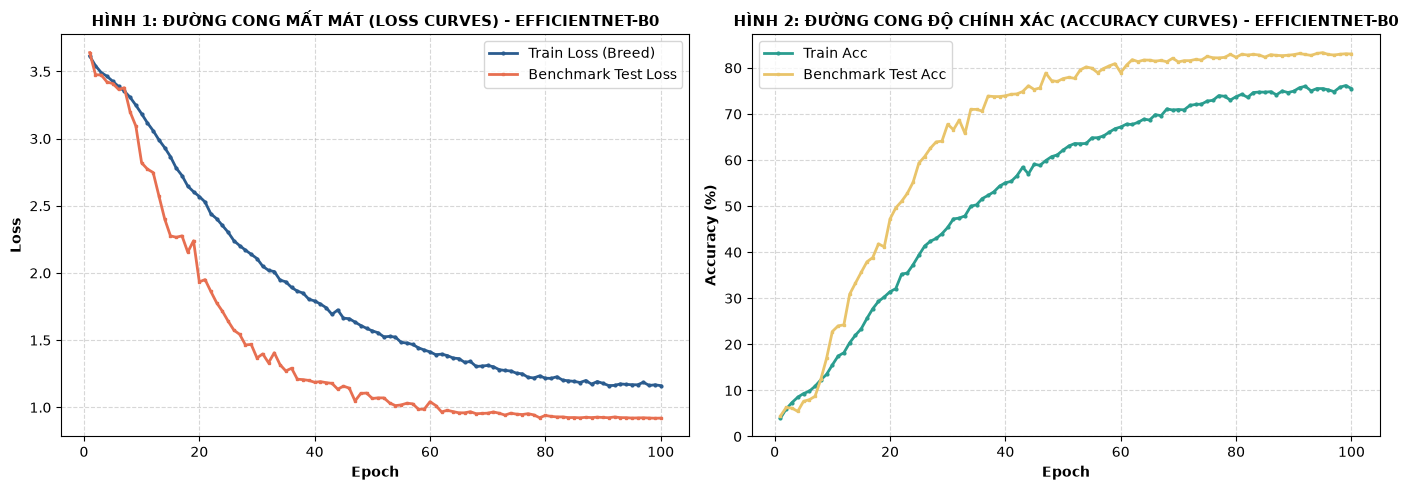

>> Đã nạp trọng số tối ưu nhất: Epoch 95 (Best Raw Benchmark Acc: 83.32%)

              KẾT QUẢ ĐỐI SÁNH HIỆU NĂNG EFFICIENTNET-B0 TRÊN BENCHMARK OXFORD-IIIT PET                   
  * Quy mô dữ liệu huấn luyện mở rộng (Expanded Train): 9,301 ảnh (Oxford + New Dataset)
  * Quy mô dữ liệu kiểm thử chuẩn (Canonical Test)   : 3,669 ảnh (100% Oxford-IIIT Pet)
  * Tổng số tham số mô hình (Trainable Parameters)    : 4,045,605 (~4.05M)
  * Trọng số tối ưu đạt tại                           : Epoch 95
----------------------------------------------------------------------------------------------------------
  1. Test Accuracy Chuẩn (Không dùng TTA)             : 83.32%
  2. Test Accuracy Tối Ưu (Sử dụng 4-View Multi-TTA)  : 83.78%
  >> Mức tăng trưởng đạt được nhờ 4-View TTA          : +0.46%



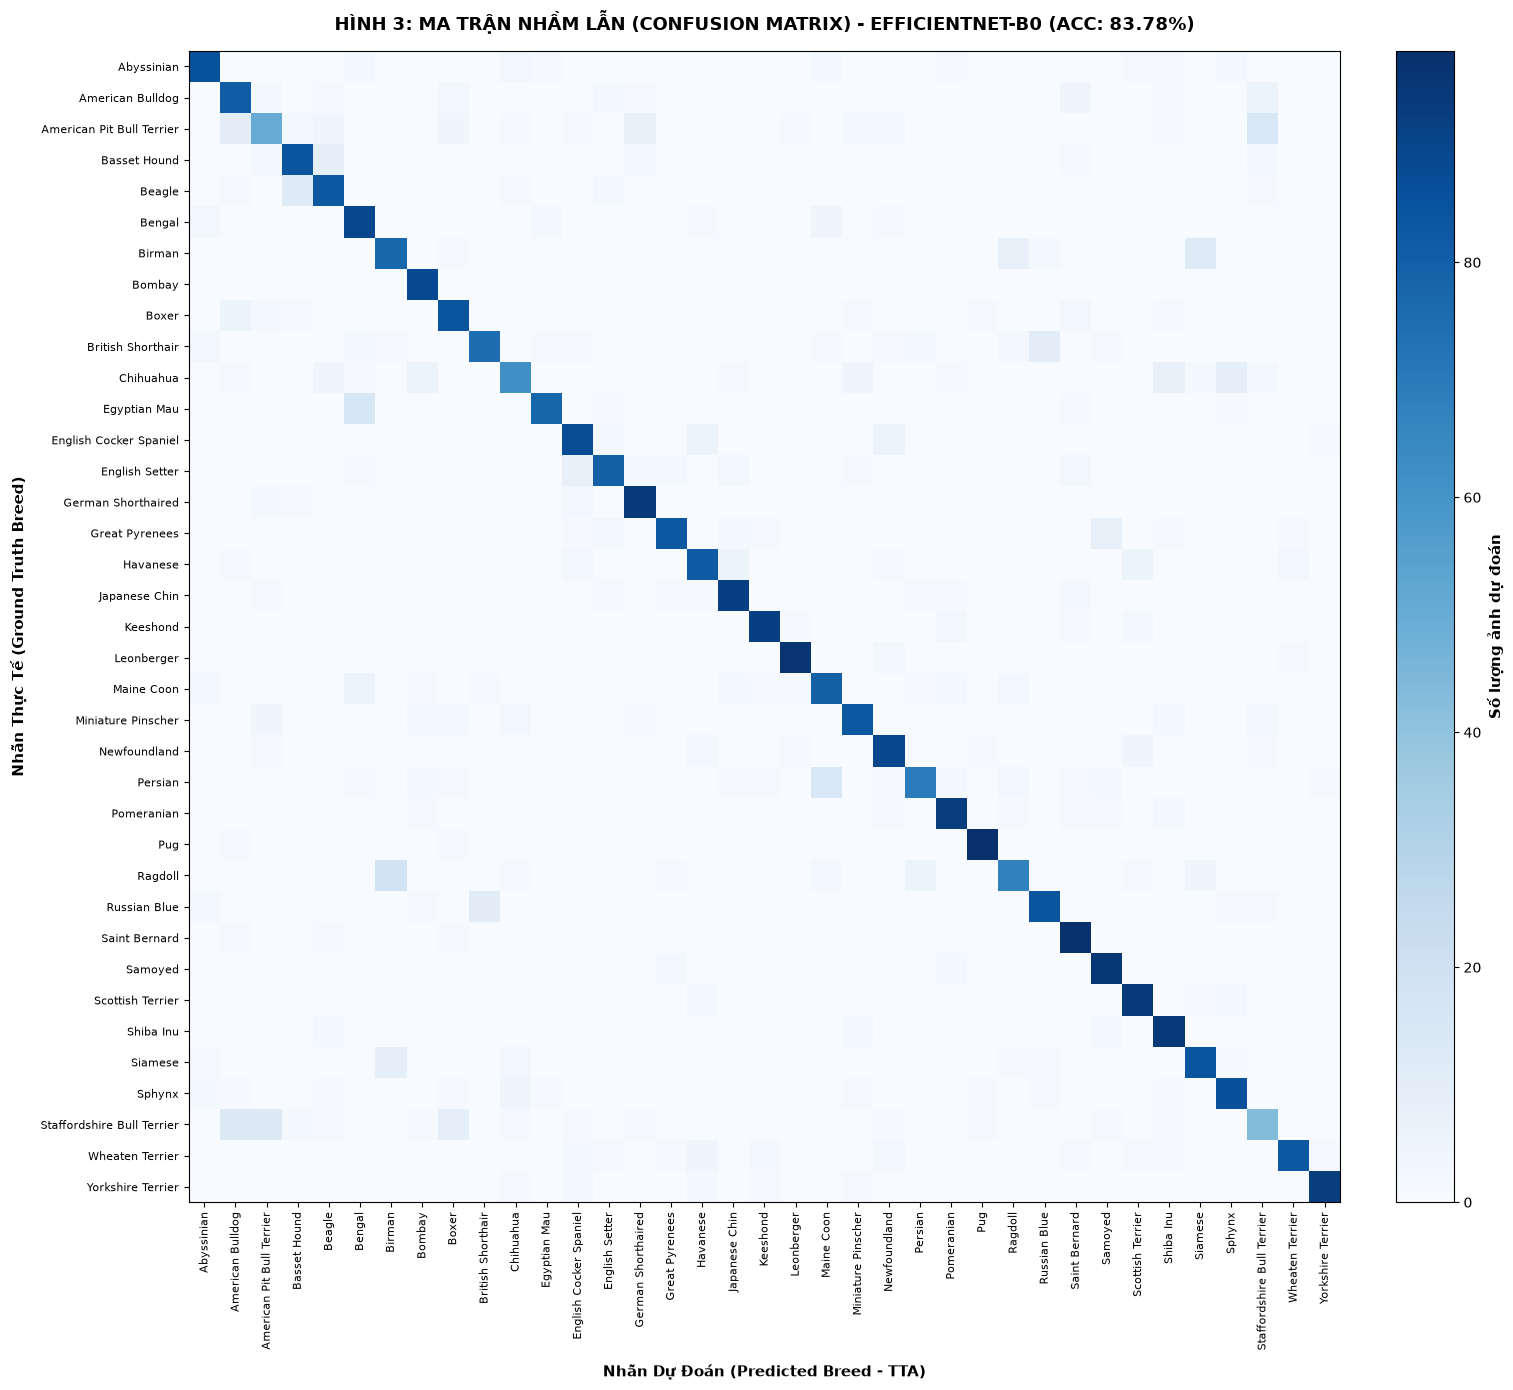

Đã lưu kết quả đối sánh định lượng tại: ./plots/efficientnet_b0_metrics.json


In [7]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader

os.makedirs(args.plots_dir, exist_ok=True)
if "best_ckpt" not in locals():
    best_ckpt = os.path.join(args.checkpoint_dir, "efficientnet_b0_augmented_best.pth")
epochs_range = range(1, len(train_losses) + 1)

# 1. Vẽ đường cong Loss & Accuracy theo Epoch
try:
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, train_losses, "o-", label="Train Loss (Breed)", color="#2b5c8f", lw=2, markersize=2)
    plt.plot(epochs_range, test_losses, "s-", label="Benchmark Test Loss", color="#e76f51", lw=2, markersize=2)
    plt.title("HÌNH 1: ĐƯỜNG CONG MẤT MÁT (LOSS CURVES) - EFFICIENTNET-B0", fontweight="bold", fontsize=11)
    plt.xlabel("Epoch", fontweight="bold")
    plt.ylabel("Loss", fontweight="bold")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, train_accs, "o-", label="Train Acc", color="#2a9d8f", lw=2, markersize=2)
    plt.plot(epochs_range, test_accs, "s-", label="Benchmark Test Acc", color="#e9c46a", lw=2, markersize=2)
    plt.title("HÌNH 2: ĐƯỜNG CONG ĐỘ CHÍNH XÁC (ACCURACY CURVES) - EFFICIENTNET-B0", fontweight="bold", fontsize=11)
    plt.xlabel("Epoch", fontweight="bold")
    plt.ylabel("Accuracy (%)", fontweight="bold")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()

    plt.tight_layout()
    curve_path = os.path.join(args.plots_dir, "efficientnet_b0_curves.png")
    plt.savefig(curve_path, dpi=300)
    plt.show()
except Exception as e:
    print(f">> Cảnh báo khi vẽ đồ thị: {e}")

# 2. Nạp lại trọng số tốt nhất trước khi đánh giá chuẩn & 4-View TTA
if os.path.exists(best_ckpt):
    best_ckpt_data = torch.load(best_ckpt, map_location=device, weights_only=False)
    model.load_state_dict(best_ckpt_data["model_state_dict"])
    best_epoch_num = best_ckpt_data["epoch"]
    best_raw_acc_val = best_ckpt_data["best_acc"]
    print(f">> Đã nạp trọng số tối ưu nhất: Epoch {best_epoch_num:02d} (Best Raw Benchmark Acc: {best_raw_acc_val:.2f}%)")

model.eval()

# 3. Đánh giá kiểm thử với 4-View Multi-Scale TTA trên Benchmark Oxford Chuẩn (3.669 ảnh)
all_preds_raw, all_preds_tta, all_targets = [], [], []
eval_loader = DataLoader(testset, batch_size=args.batch_size, shuffle=False, num_workers=0)

with torch.no_grad():
    for inputs, targets, _ in eval_loader:
        inputs = inputs.to(device)
        targets = targets.numpy()

        # View 1: Ảnh gốc
        p1 = F.softmax(model(inputs), dim=1)
        preds_raw = p1.max(1)[1].cpu().numpy()

        # View 2: Lật ngang Horizontal Flip
        p2 = F.softmax(model(torch.flip(inputs, dims=[-1])), dim=1)

        # View 3: Cắt trọng tâm và phóng to 1.1x (Zoomed View)
        h, w = inputs.shape[2], inputs.shape[3]
        h_c, w_c = int(h * 0.9), int(w * 0.9)
        top, left = (h - h_c) // 2, (w - w_c) // 2
        crop = inputs[:, :, top:top+h_c, left:left+w_c]
        inputs_zoom = F.interpolate(crop, size=(h, w), mode="bilinear", align_corners=False)
        p3 = F.softmax(model(inputs_zoom), dim=1)

        # View 4: Phóng to kết hợp lật ngang
        p4 = F.softmax(model(torch.flip(inputs_zoom, dims=[-1])), dim=1)

        # Weighted Ensemble: 40% Gốc + 30% Flip + 15% Zoom + 15% Zoom-Flip
        probs_tta = (p1 * 0.4) + (p2 * 0.3) + (p3 * 0.15) + (p4 * 0.15)
        preds_tta = probs_tta.max(1)[1].cpu().numpy()

        all_preds_raw.extend(preds_raw)
        all_preds_tta.extend(preds_tta)
        all_targets.extend(targets)

acc_raw = 100.0 * np.mean(np.array(all_preds_raw) == np.array(all_targets))
acc_tta = 100.0 * np.mean(np.array(all_preds_tta) == np.array(all_targets))

print()
print("==========================================================================================================")
print("              KẾT QUẢ ĐỐI SÁNH HIỆU NĂNG EFFICIENTNET-B0 TRÊN BENCHMARK OXFORD-IIIT PET                   ")
print("==========================================================================================================")
print(f"  * Quy mô dữ liệu huấn luyện mở rộng (Expanded Train): {len(trainset):,} ảnh (Oxford + New Dataset)")
print(f"  * Quy mô dữ liệu kiểm thử chuẩn (Canonical Test)   : {len(testset):,} ảnh (100% Oxford-IIIT Pet)")
print(f"  * Tổng số tham số mô hình (Trainable Parameters)    : {total_params:,} (~{total_params/1e6:.2f}M)")
print(f"  * Trọng số tối ưu đạt tại                           : Epoch {best_epoch_num:02d}")
print("----------------------------------------------------------------------------------------------------------")
print(f"  1. Test Accuracy Chuẩn (Không dùng TTA)             : {acc_raw:.2f}%")
print(f"  2. Test Accuracy Tối Ưu (Sử dụng 4-View Multi-TTA)  : {acc_tta:.2f}%")
print(f"  >> Mức tăng trưởng đạt được nhờ 4-View TTA          : +{acc_tta - acc_raw:.2f}%")
print("==========================================================================================================")
print()

# 4. Ma trận nhầm lẫn (Confusion Matrix) trên 37 loài với TTA (Phòng vệ an toàn)
try:
    if "classes" not in locals() or classes is None:
        classes = getattr(testset, "class_names", [f"Class {i}" for i in range(37)])
    num_classes = len(classes)
    cm = confusion_matrix(all_targets, all_preds_tta, labels=list(range(num_classes)))
    breed_names = [name.replace("_", " ").title() for name in classes]

    plt.figure(figsize=(16, 14))
    im = plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
    plt.title(f"HÌNH 3: MA TRẬN NHẦM LẪN (CONFUSION MATRIX) - EFFICIENTNET-B0 (ACC: {acc_tta:.2f}%)", fontweight="bold", fontsize=13, pad=15)
    cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
    cbar.set_label("Số lượng ảnh dự đoán", fontweight="bold", fontsize=11)

    tick_marks = np.arange(len(breed_names))
    plt.xticks(tick_marks, breed_names, rotation=90, fontsize=8)
    plt.yticks(tick_marks, breed_names, fontsize=8)

    plt.xlabel("Nhãn Dự Đoán (Predicted Breed - TTA)", fontweight="bold", fontsize=11, labelpad=10)
    plt.ylabel("Nhãn Thực Tế (Ground Truth Breed)", fontweight="bold", fontsize=11, labelpad=10)
    plt.tight_layout()
    cm_path = os.path.join(args.plots_dir, "efficientnet_b0_confusion_matrix.png")
    plt.savefig(cm_path, dpi=300, bbox_inches="tight")
    plt.show()
except Exception as e:
    print(f">> Cảnh báo khi xuất ma trận nhầm lẫn: {e}")

# 5. Xuất file tóm tắt chỉ số định lượng
try:
    metrics_summary = {
        "model_name": "EfficientNet-B0 (Tan & Le, 2019 Table 1 - From Scratch)",
        "total_params": total_params,
        "img_size": args.img_size,
        "batch_size": args.batch_size,
        "epochs_trained": len(train_losses),
        "train_samples": len(trainset),
        "test_samples": len(testset),
        "best_epoch": int(best_epoch_num),
        "final_train_loss": round(train_losses[-1], 3) if train_losses else None,
        "final_train_acc": round(train_accs[-1], 2) if train_accs else None,
        "final_test_loss": round(test_losses[-1], 3) if test_losses else None,
        "final_test_acc": round(test_accs[-1], 2) if test_accs else None,
        "best_benchmark_test_acc_raw": round(acc_raw, 2),
        "best_benchmark_test_acc_tta": round(acc_tta, 2),
        "delta_tta_gain": round(acc_tta - acc_raw, 2)
    }
    metrics_file = os.path.join(args.plots_dir, "efficientnet_b0_metrics.json")
    with open(metrics_file, "w") as f:
        json.dump(metrics_summary, f, indent=2)
    print(f"Đã lưu kết quả đối sánh định lượng tại: {metrics_file}")
except Exception as e:
    print(f">> Cảnh báo khi lưu file metrics: {e}")
